# 🧪 Simulación de clientes nuevos: ¿desde cuántas compras conviene personalizar?
**Lookwise Data Lab** · Sistema de recomendación para clientes nuevos de H&M (e-commerce)
**Autora:** Margot Huaman Quispe · **Fase:** Evaluación complementaria
**Continúa:** `04_pipeline_modelos.ipynb` (modelos y modelo final)

---

## 🎯 Pregunta de negocio
Hoy a un cliente nuevo se le muestra **lo más vendido**. Apenas compra algo, ya sabemos qué le gusta. **¿A partir de cuántas compras un modelo personalizado le gana a lo más vendido?** Esa respuesta define **cuándo cambiar** de vitrina general a vitrina personalizada.

**Por qué simular:** en la semana de test hay solo **437 clientes nuevos reales**, y con ellos ningún modelo superó a lo más vendido de forma concluyente. Para responder con más evidencia, tomamos clientes que **sí** tienen historial y les **"borramos" el pasado**, dejando visibles solo 0, 1 o 2 compras. Así se comportan como clientes recién llegados, pero sabemos qué compraron después.

> 🎭 **Como un ensayo general:** no tenemos suficientes clientes nuevos de verdad, así que "disfrazamos" de nuevos a clientes conocidos y miramos cómo les va a los modelos.

## 📏 Reglas de la simulación (fijadas antes de ver resultados)

| # | Regla | Decisión | Por qué |
|---|---|---|---|
| 1 | **Quién entra** | Clientes que compran en la semana de test (16–22/09/2020) y que antes compraron **al menos 3 artículos distintos** | Así, aun con 2 compras visibles, siempre queda historial oculto. Es el **mismo grupo** en todos los escenarios: solo cambia cuánto se ve |
| 2 | **Cuántas compras quedan visibles** | **0, 1 y 2** (y el historial completo como referencia) | 0 = cliente recién llegado; 1 y 2 = sus primeras compras |
| 3 | **Cuáles quedan visibles** | Las **más recientes** (escenario principal); las **primeras** de su vida como control | Un cliente nuevo real acaba de llegar: sus primeras compras son de los últimos días, no de hace dos años |
| 4 | **Regla contra la fuga de información** | Las compras ocultas se **borran de toda la base**: no cuentan para la popularidad, los pares de co-compra ni el entrenamiento del ranker. Solo se usan compras anteriores al 16/09 | Si quedaran en algún lado, el modelo "recordaría" lo que se supone que no sabe |
| 5 | **Qué se evalúa** | Lo que esos clientes compran en la **misma semana de test** (16–22/09/2020) | Comparable con los resultados del notebook 02 |
| 6 | **Métricas** | **MAP@12** (principal) y **Hit Rate@12**, con **intervalo de confianza del 95%** (bootstrap pareado) | Las mismas del proyecto; el intervalo dice si la diferencia es real o azar |
| 7 | **Criterio de éxito** | Un modelo **le gana a lo más vendido** con N compras si mejora MAP@12 **y** Hit Rate@12 **y** el intervalo de la mejora en MAP@12 **no incluye el 0**. El **umbral** es el menor N desde el cual eso se cumple | Mismo criterio que las hipótesis del notebook 02 |
| 8 | **Cómo se reporta** | **Simulados y reales por separado** | Los simulados son una aproximación; los reales son la evidencia directa |
| 9 | **Modelos que entran** | Baseline (lo más vendido 7 días), Modelo 1 (edad), Modelo 2 (co-compra) y Modelo 3 (ranker con regresión logística) | Los mismos parámetros elegidos en validación en el notebook 02 |

> ⚠️ Los resultados y la **📌 Lectura automática** aparecen al ejecutar **▷ Run All**. Tarda unos **20–30 minutos**: el ranker se vuelve a entrenar en cada escenario, porque la base cambia.

---
## ⚙️ Configuración
**▶️ Qué hace:** trae las herramientas y nuestros scripts. Los **parámetros de los modelos son los elegidos en validación en el notebook 02**: no se vuelven a ajustar acá, para no acomodarlos a la simulación.

In [10]:
import os, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, os.path.abspath("../src"))
from datos import cargar, tratar, separar, clientes_frios, CORTE_TEST
from metricas import compras_por_cliente, metricas, bootstrap_diferencia, tabla_bonita
from simulacion import (elegir_clientes, ocultar_historial, modelos_escenario, evaluar_escenario,
                        umbral, MIN_ARTICULOS, VISIBLES, COMPLETO)

BASE = "E:/Descargas_Henry/PF_HM/datos/p10"   # <- carpeta local de la muestra p10 (no se sube al repo)
FIG_DIR, OUT_DIR = "../reports/figures", "../reports"
os.makedirs(FIG_DIR, exist_ok=True)

# Parámetros elegidos en validación (notebook 02)
PARAMS = {"dias_baseline": 7, "dias_edad": 30, "dias_pares": 28, "peso_recompra": 1.0, "algoritmo": "logreg"}

AZUL, NARANJA, VERDE, VIOLETA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a5cd6", "#9a9993"
COLOR = {"Baseline": GRIS, "M1 · Edad": NARANJA, "M2 · Co-compra": AZUL, "M3 · Ranker": VERDE}
TEXTO, TEXTO2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#d6d5cf",
    "axes.labelcolor": TEXTO2, "xtick.color": TEXTO2, "ytick.color": TEXTO2,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#ecebe6", "grid.linewidth": 0.8,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "legend.frameon": False,
})
def guardar(fig, nombre):
    fig.savefig(f"{FIG_DIR}/{nombre}.png", bbox_inches="tight", facecolor="white")
print("📌 Lectura: herramientas cargadas ✅ · parámetros del notebook 02:", PARAMS)

📌 Lectura: herramientas cargadas ✅ · parámetros del notebook 02: {'dias_baseline': 7, 'dias_edad': 30, 'dias_pares': 28, 'peso_recompra': 1.0, 'algoritmo': 'logreg'}


---
# 1. Datos y clientes de la simulación

### ▶️ Paso 1.1 · Cargar, tratar y separar
**Qué hace:** repite exactamente el tratamiento y la partición del notebook 02 (train hasta el 15/09, test 16–22/09).

In [11]:
trans, cust, art = cargar(BASE)
trans, cust, art, _ = tratar(trans, cust, art)
train, test = separar(trans, CORTE_TEST)
tramo = cust.set_index("customer_id")["tramo_edad"].to_dict()
compras_test = compras_por_cliente(test)
frios = clientes_frios(trans, CORTE_TEST)
print(f"📌 Lectura: {len(train):,} compras de entrenamiento y {len(compras_test):,} clientes que compran en el test "
      f"({len(frios & set(compras_test)):,} son clientes nuevos reales).")

📌 Lectura: 2,210,154 compras de entrenamiento y 4,162 clientes que compran en el test (437 son clientes nuevos reales).


### ▶️ Paso 1.2 · Elegir quién entra a la simulación (regla 1)
**Qué hace:** se queda con los clientes del test que antes compraron **al menos 3 artículos distintos**.

**Por qué:** si un cliente tuviera solo 2 compras, al dejarle "2 visibles" no le estaríamos ocultando nada y no se parecería a un cliente nuevo.

In [12]:
clientes_sim = elegir_clientes(train, compras_test, MIN_ARTICULOS)
compras_sim = {c: compras_test[c] for c in clientes_sim}
hist = train[train["customer_id"].isin(clientes_sim)].groupby("customer_id")["article_id"].nunique()
print(f"📌 Lectura: entran {len(clientes_sim):,} clientes simulados "
      f"({len(clientes_sim) / len(compras_test):.0%} de los que compran en el test).")
print(f"   Antes del corte compraron en mediana {hist.median():.0f} artículos distintos: "
      f"al dejar 0, 1 o 2 visibles se oculta casi todo su pasado.")
print(f"   Son {len(clientes_sim) / max(len(frios & set(compras_test)), 1):.1f} veces más clientes que los nuevos reales: "
      "más evidencia para decidir.")

📌 Lectura: entran 3,549 clientes simulados (85% de los que compran en el test).
   Antes del corte compraron en mediana 33 artículos distintos: al dejar 0, 1 o 2 visibles se oculta casi todo su pasado.
   Son 8.1 veces más clientes que los nuevos reales: más evidencia para decidir.


### ▶️ Paso 1.3 · Control anti-fuga (regla 4)
**Qué hace:** arma la base de cada escenario y **verifica** que a ningún cliente simulado le quedaron más artículos visibles de los permitidos, y que no se usó ninguna compra posterior al 15/09.

> 🔒 **Como tapar las respuestas de un examen:** si queda una sola respuesta a la vista, la nota ya no vale. Este control revisa que todo esté tapado.

In [13]:
bases = {}
filas = []
for cuales in ["recientes", "primeras"]:
    for n in VISIBLES:
        b = ocultar_historial(train, clientes_sim, n, cuales)
        bases[(n, cuales)] = b
        vis = b[b["customer_id"].isin(clientes_sim)].groupby("customer_id")["article_id"].nunique()
        filas.append({"Cuáles": cuales, "Compras visibles": n,
                      "Máx. artículos visibles por cliente": int(vis.max()) if len(vis) else 0,
                      "Compras borradas de la base": len(train) - len(b),
                      "Fecha máxima usada": b["t_dat"].max().date(),
                      "OK": "✅" if (len(vis) == 0 or vis.max() <= n) and b["t_dat"].max() < CORTE_TEST else "❌"})
bases[(COMPLETO, "recientes")] = train
control = pd.DataFrame(filas)
print("📌 Lectura:", "todos los escenarios respetan la regla anti-fuga ✅" if (control["OK"] == "✅").all()
      else "⚠️ algún escenario NO respeta la regla: revisar antes de seguir")
control

📌 Lectura: todos los escenarios respetan la regla anti-fuga ✅


,Cuáles,Compras visibles,Máx. artículos visibles por cliente,Compras borradas de la base,Fecha máxima usada,OK
0,recientes,0,0,236716,2020-09-15,✅
1,recientes,1,1,232601,2020-09-15,✅
2,recientes,2,2,228522,2020-09-15,✅
3,primeras,0,0,236716,2020-09-15,✅
4,primeras,1,1,232638,2020-09-15,✅
5,primeras,2,2,228627,2020-09-15,✅


---
# 2. Escenario principal: las compras visibles son las más recientes

### ▶️ Paso 2.1 · Entrenar y evaluar cada escenario
**Qué hace:** para 0, 1 y 2 compras visibles (y el historial completo como referencia):
1. Entrena **los cuatro modelos** con la base de ese escenario.
2. Recomienda 12 prendas a cada cliente simulado.
3. Mide MAP@12 y Hit Rate@12, y la diferencia con lo más vendido con su intervalo del 95%.

**Por qué se entrena de nuevo en cada escenario:** al borrar compras cambian la popularidad, los pares de co-compra y los ejemplos del ranker. Usar los modelos del notebook 02 sería hacer trampa (regla 4).

In [14]:
resultados = []
modelos_por_escenario = {}
for n in VISIBLES + [COMPLETO]:
    inicio = time.time()
    mods = modelos_escenario(bases[(n, "recientes")], CORTE_TEST, tramo, cust, art, clientes_sim, PARAMS)
    modelos_por_escenario[n] = mods
    resultados.append(evaluar_escenario(mods, compras_sim, n, "recientes"))
    print(f"   escenario {str(n):>9}: listo en {time.time() - inicio:,.0f} s")
res = pd.concat(resultados, ignore_index=True)

vista = res.assign(**{"Hit Rate@12 (%)": (res["Hit Rate@12"] * 100).round(2), "MAP@12": res["MAP@12"].round(4),
                      "Dif. MAP@12 vs baseline": res["Dif. MAP@12 vs baseline"].round(4),
                      "IC 95%": res.apply(lambda r: "" if pd.isna(r["IC bajo"]) else f"[{r['IC bajo']:+.4f}, {r['IC alto']:+.4f}]", axis=1),
                      "¿Le gana?": res["Le gana al baseline"].map({True: "✅ sí", False: "—"}).fillna("referencia")})
vista = vista[["Compras visibles", "Modelo", "Clientes", "MAP@12", "Hit Rate@12 (%)", "Dif. MAP@12 vs baseline", "IC 95%", "¿Le gana?"]]
print("📌 Lectura por escenario (Hit Rate@12 = clientes de cada 100 que compran algo de la lista):")
for n in VISIBLES + [COMPLETO]:
    r = res[res["Compras visibles"] == str(n)].set_index("Modelo")
    mejor = r["MAP@12"].idxmax()
    etiqueta = "historial completo" if n == COMPLETO else f"{n} compra{'s' if n != 1 else ''} visible{'s' if n != 1 else ''}"
    print(f"   {etiqueta:<22}: lo más vendido {r.loc['Baseline', 'Hit Rate@12'] * 100:4.1f} · mejor {mejor} "
          f"{r.loc[mejor, 'Hit Rate@12'] * 100:4.1f} de cada 100"
          + (" ✅ gana" if mejor != "Baseline" and r.loc[mejor, "Le gana al baseline"] == True else ""))
vista

   escenario         0: listo en 272 s
   escenario         1: listo en 177 s
   escenario         2: listo en 159 s
   escenario  completo: listo en 159 s
📌 Lectura por escenario (Hit Rate@12 = clientes de cada 100 que compran algo de la lista):
   0 compras visibles    : lo más vendido  5.9 · mejor M3 · Ranker  7.2 de cada 100 ✅ gana
   1 compra visible      : lo más vendido  5.9 · mejor M2 · Co-compra  8.2 de cada 100 ✅ gana
   2 compras visibles    : lo más vendido  6.6 · mejor M3 · Ranker 12.1 de cada 100 ✅ gana
   historial completo    : lo más vendido  7.2 · mejor M3 · Ranker 14.0 de cada 100 ✅ gana


,Compras visibles,Modelo,Clientes,MAP@12,Hit Rate@12 (%),Dif. MAP@12 vs baseline,IC 95%,¿Le gana?
0,0,Baseline,3549,0.0053,5.92,NaN,,referencia
1,0,M1 · Edad,3549,0.0056,5.75,0.0003,"[-0.0013, +0.0018]",—
2,0,M2 · Co-compra,3549,0.0056,5.75,0.0003,"[-0.0013, +0.0018]",—
3,0,M3 · Ranker,3549,0.0077,7.19,0.0023,"[+0.0012, +0.0036]",✅ sí
4,1,Baseline,3549,0.0061,5.92,NaN,,referencia
5,1,M1 · Edad,3549,0.0056,5.66,-0.0005,"[-0.0023, +0.0013]",—
6,1,M2 · Co-compra,3549,0.0274,8.23,0.0213,"[+0.0166, +0.0256]",✅ sí
7,1,M3 · Ranker,3549,0.0273,10.57,0.0212,"[+0.0170, +0.0253]",✅ sí
8,2,Baseline,3549,0.0064,6.59,NaN,,referencia
9,2,M1 · Edad,3549,0.0055,5.69,-0.0008,"[-0.0027, +0.0010]",—


### ▶️ Paso 2.2 · Gráfico: cuánto acierta cada modelo según las compras que conoce
**Qué muestra:** una línea por modelo. La línea **gris punteada** es lo más vendido: todo lo que queda **por encima** es mejor que lo que se hace hoy.

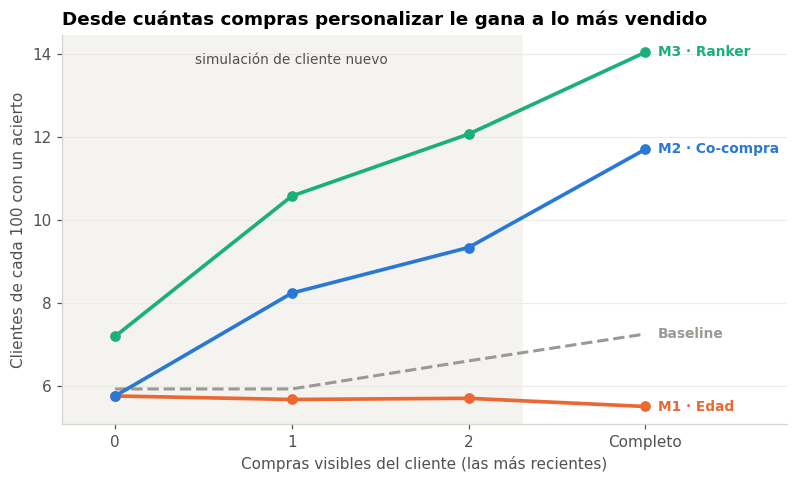

📌 Lectura: la zona gris es la simulación; 'Completo' es la referencia con todo el historial.


In [15]:
etiquetas = ["0", "1", "2", "Completo"]
claves = [str(n) for n in VISIBLES] + [COMPLETO]
fig, ax = plt.subplots(figsize=(8.5, 4.6))
for modelo, color in COLOR.items():
    serie = [res[(res["Compras visibles"] == k) & (res["Modelo"] == modelo)]["Hit Rate@12"].iloc[0] * 100 for k in claves]
    estilo = dict(ls="--", lw=2) if modelo == "Baseline" else dict(lw=2.4, marker="o", ms=6)
    ax.plot(etiquetas, serie, color=color, **estilo)
    ax.annotate(modelo, (etiquetas[-1], serie[-1]), xytext=(8, 0), textcoords="offset points",
                va="center", color=color, fontsize=9, fontweight="bold")
ax.axvspan(-0.3, 2.3, color="#f4f3ef", zorder=0)
ax.text(1, ax.get_ylim()[1] * 0.97, "simulación de cliente nuevo", ha="center", va="top", color=TEXTO2, fontsize=9)
ax.set_xlabel("Compras visibles del cliente (las más recientes)")
ax.set_ylabel("Clientes de cada 100 con un acierto")
ax.set_title("Desde cuántas compras personalizar le gana a lo más vendido")
ax.set_xlim(-0.3, 3.8)
guardar(fig, "21_simulacion_hit_rate")
plt.show()
print("📌 Lectura: la zona gris es la simulación; 'Completo' es la referencia con todo el historial.")

### ▶️ Paso 2.3 · ¿La mejora es real o puede ser azar?
**Qué muestra:** para cada modelo personalizado, cuánto mejora el **MAP@12** frente a lo más vendido (punto) y su **intervalo del 95%** (línea). Si la línea queda **toda por encima del 0**, la mejora es real.

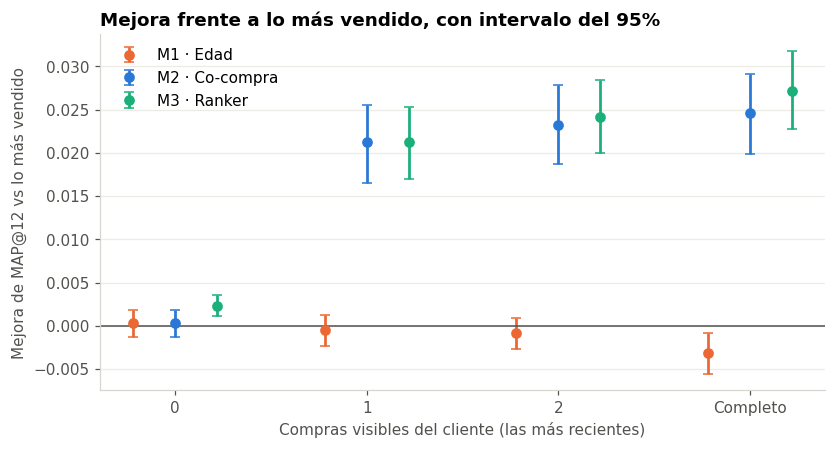

📌 Lectura: punto = mejora promedio; línea = intervalo del 95%. Por encima del 0 sin tocarlo = mejora real.


In [16]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
modelos_p = ["M1 · Edad", "M2 · Co-compra", "M3 · Ranker"]
ancho = 0.22
for j, modelo in enumerate(modelos_p):
    for i, k in enumerate(claves):
        r = res[(res["Compras visibles"] == k) & (res["Modelo"] == modelo)].iloc[0]
        x = i + (j - 1) * ancho
        ax.errorbar(x, r["Dif. MAP@12 vs baseline"], yerr=[[r["Dif. MAP@12 vs baseline"] - r["IC bajo"]], [r["IC alto"] - r["Dif. MAP@12 vs baseline"]]],
                    fmt="o", color=COLOR[modelo], ms=6, capsize=3, lw=1.8, label=modelo if i == 0 else None)
ax.axhline(0, color=TEXTO2, lw=1)
ax.set_xticks(range(len(claves)), etiquetas)
ax.set_xlabel("Compras visibles del cliente (las más recientes)")
ax.set_ylabel("Mejora de MAP@12 vs lo más vendido")
ax.set_title("Mejora frente a lo más vendido, con intervalo del 95%")
ax.legend(loc="upper left")
guardar(fig, "22_simulacion_intervalos")
plt.show()
print("📌 Lectura: punto = mejora promedio; línea = intervalo del 95%. Por encima del 0 sin tocarlo = mejora real.")

---
# 3. Control de sensibilidad: ¿y si las visibles son las primeras compras de su vida?
**Qué hace:** repite la simulación dejando visibles las **primeras** compras del cliente en lugar de las más recientes (sin el ranker, para no duplicar el tiempo de cálculo).

**Por qué:** si la conclusión cambia mucho según qué compras se ven, hay que decirlo. Si se mantiene, la conclusión es más sólida.

In [17]:
sens = []
for n in VISIBLES:
    mods = modelos_escenario(bases[(n, "primeras")], CORTE_TEST, tramo, cust, art, clientes_sim, PARAMS, con_ranker=False)
    sens.append(evaluar_escenario(mods, compras_sim, n, "primeras"))
sens = pd.concat(sens, ignore_index=True)
todo = pd.concat([res, sens], ignore_index=True)
comp = (todo[todo["Modelo"].isin(["Baseline", "M2 · Co-compra"]) & (todo["Compras visibles"] != COMPLETO)]
        .pivot_table(index="Compras visibles", columns=["Cuáles", "Modelo"], values="Hit Rate@12") * 100).round(1)
u_rec, u_pri = umbral(todo, "M2 · Co-compra", "recientes"), umbral(todo, "M2 · Co-compra", "primeras")
txt = lambda u: "no le gana con 0, 1 ni 2" if u is None else f"le gana desde {u} compra{'s' if u != 1 else ''}"
print(f"📌 Lectura · Modelo 2 (co-compra): con las más recientes {txt(u_rec)}; con las primeras {txt(u_pri)}.")
print("   " + ("✅ La conclusión no depende de qué compras se ven." if u_rec == u_pri
             else "⚠️ La conclusión cambia: las compras recientes informan más que las antiguas (la moda cambia rápido, H4)."))
comp

📌 Lectura · Modelo 2 (co-compra): con las más recientes le gana desde 1 compra; con las primeras no le gana con 0, 1 ni 2.
   ⚠️ La conclusión cambia: las compras recientes informan más que las antiguas (la moda cambia rápido, H4).


Cuáles           primeras                recientes               
Modelo           Baseline M2 · Co-compra  Baseline M2 · Co-compra
Compras visibles                                                 
0                     5.9            5.7       5.9            5.7
1                     5.9            5.5       5.9            8.2
2                     5.9            4.9       6.6            9.3

---
# 4. Simulados y reales, por separado (regla 8)
**Qué hace:** pone lado a lado el escenario **"0 compras visibles"** de la simulación y los **clientes nuevos reales** de la semana de test, evaluados con los modelos entrenados con toda la base.

**Por qué:** si los dos cuentan la misma historia, la simulación es creíble para los escenarios de 1 y 2 compras, donde no hay datos reales.

In [18]:
mods_reales = modelos_por_escenario[COMPLETO]
compras_frios = {c: a for c, a in compras_test.items() if c in frios}
mods_reales["M3 · Ranker"].preparar(list(compras_frios))
filas = []
for nombre, m in mods_reales.items():
    filas.append({"Modelo": nombre, "Grupo": f"Nuevos reales ({len(compras_frios)})", **metricas(compras_frios, m.recomendar)})
for _, r in res[res["Compras visibles"] == "0"].iterrows():
    filas.append({"Modelo": r["Modelo"], "Grupo": f"Simulados, 0 visibles ({r['Clientes']:,})",
                  **{k: r[k] for k in ["MAP@12", "Hit Rate@12", "Recall@12", "Precision@12", "Prendas distintas"]}})
sep = pd.DataFrame(filas)
tabla_sep = (sep.pivot_table(index="Modelo", columns="Grupo", values="Hit Rate@12") * 100).round(1)
gana_real = tabla_sep.iloc[:, 0].idxmax(); gana_sim = tabla_sep.iloc[:, 1].idxmax()
print(f"📌 Lectura: sin compras visibles, el mejor en reales es {gana_real} y en simulados es {gana_sim}.")
print("   " + ("✅ Coinciden: la simulación reproduce lo que pasa con clientes nuevos de verdad." if gana_real == gana_sim
             else "⚠️ No coinciden del todo: los simulados ya eran compradores frecuentes; se reporta con esa salvedad."))
tabla_sep

📌 Lectura: sin compras visibles, el mejor en reales es Baseline y en simulados es M3 · Ranker.
   ⚠️ No coinciden del todo: los simulados ya eran compradores frecuentes; se reporta con esa salvedad.


Grupo,Nuevos reales (437),"Simulados, 0 visibles (3,549)"
Modelo,,
Baseline,4.6,5.9
M1 · Edad,4.3,5.7
M2 · Co-compra,4.3,5.7
M3 · Ranker,3.7,7.2


---
# 5. Conclusión: ¿cuándo dejar de mostrar lo más vendido?

In [19]:
# Regla 8: con 0 compras manda la evidencia REAL (clientes nuevos de verdad); con 1 o 2, la simulación.
mejor_real0 = tabla_sep.iloc[:, 0].idxmax()
def umbral_con_compras(modelo):
    r = res[(res["Modelo"] == modelo) & res["Compras visibles"].isin(["1", "2"])].sort_values("Compras visibles")
    gana = r["Le gana al baseline"].fillna(False).astype(bool).tolist()
    for i, n in enumerate([1, 2]):
        if all(gana[i:]):
            return n
    return None
u = {m: umbral_con_compras(m) for m in ["M1 · Edad", "M2 · Co-compra", "M3 · Ranker"]}
candidatos = {m: n for m, n in u.items() if n is not None}
print("=" * 84)
print("🎯 RESPUESTA: ¿A PARTIR DE CUÁNTAS COMPRAS CONVIENE PERSONALIZAR?")
print("=" * 84)
print(f"   0 compras (evidencia real, {len(compras_frios)} clientes nuevos): mejor = {mejor_real0} "
      f"({tabla_sep.loc[mejor_real0].iloc[0]:.1f} de cada 100).")
r0 = res[(res["Compras visibles"] == "0")].set_index("Modelo")
if mejor_real0 == "Baseline" and r0["Le gana al baseline"].fillna(False).any():
    print("   ⚠️ En la simulación con 0 compras algún modelo superó a lo más vendido, pero con clientes nuevos REALES no:")
    print("      los simulados eran compradores frecuentes. Se decide con la evidencia real (regla 8).")
for m, n in u.items():
    print(f"   {m:<16}: " + ("no le gana a lo más vendido con 1 ni 2 compras" if n is None
                             else f"le gana desde {n} compra{'s' if n != 1 else ''} visible{'s' if n != 1 else ''} (simulación)"))
if candidatos:
    N = min(candidatos.values())
    empatados = [m for m, n in candidatos.items() if n == N]
    prom = res[res["Modelo"].isin(empatados) & res["Compras visibles"].isin(["1", "2"])].groupby("Modelo")["MAP@12"].mean()
    MEJOR = prom.idxmax()   # mayor MAP@12 promedio con 1 y 2 compras
    rb = res[(res["Compras visibles"] == str(N)) & (res["Modelo"] == "Baseline")].iloc[0]
    rm = res[(res["Compras visibles"] == str(N)) & (res["Modelo"] == MEJOR)].iloc[0]
    print()
    print(f"✅ REGLA PARA EL MODELO FINAL:")
    print(f"   · 0 compras → {'lo más vendido de la semana' if mejor_real0 == 'Baseline' else mejor_real0}.")
    print(f"   · Desde la compra n.º {N} → {MEJOR}: {rm['Hit Rate@12'] * 100:.1f} de cada 100 clientes con acierto "
          f"vs {rb['Hit Rate@12'] * 100:.1f} con lo más vendido (MAP@12 {rm['MAP@12']:.4f} vs {rb['MAP@12']:.4f}).")
    print(f"   · Intervalo del 95% de la mejora en MAP@12: [{rm['IC bajo']:+.4f}, {rm['IC alto']:+.4f}] → no incluye el 0.")
    print(f"   · {MEJOR} se elige por tener el mayor MAP@12 promedio con 1 y 2 compras visibles.")
else:
    N, MEJOR = None, None
    print()
    print("⚠️ Con 1 o 2 compras ningún modelo le gana de forma robusta a lo más vendido:")
    print("   se mantiene lo más vendido hasta que el cliente acumule más historial.")
print("=" * 84)


🎯 RESPUESTA: ¿A PARTIR DE CUÁNTAS COMPRAS CONVIENE PERSONALIZAR?
   0 compras (evidencia real, 437 clientes nuevos): mejor = Baseline (4.6 de cada 100).
   ⚠️ En la simulación con 0 compras algún modelo superó a lo más vendido, pero con clientes nuevos REALES no:
      los simulados eran compradores frecuentes. Se decide con la evidencia real (regla 8).
   M1 · Edad       : no le gana a lo más vendido con 1 ni 2 compras
   M2 · Co-compra  : le gana desde 1 compra visible (simulación)
   M3 · Ranker     : le gana desde 1 compra visible (simulación)

✅ REGLA PARA EL MODELO FINAL:
   · 0 compras → lo más vendido de la semana.
   · Desde la compra n.º 1 → M3 · Ranker: 10.6 de cada 100 clientes con acierto vs 5.9 con lo más vendido (MAP@12 0.0273 vs 0.0061).
   · Intervalo del 95% de la mejora en MAP@12: [+0.0170, +0.0253] → no incluye el 0.
   · M3 · Ranker se elige por tener el mayor MAP@12 promedio con 1 y 2 compras visibles.


### 🔎 Interpretación para el negocio
- **Con 0 compras manda la evidencia real:** con los 437 clientes nuevos de verdad, **lo más vendido de la semana** sigue siendo la mejor vitrina (4,6 de cada 100; el ranker, 3,7). En la simulación el ranker ganó con 0 compras, pero los simulados eran compradores frecuentes: por eso los resultados se leen separados (regla 8).
- **Desde la primera compra conviene personalizar:** con una sola compra visible, el ranker acierta a **10,6 de cada 100 clientes** frente a 5,9 con lo más vendido, casi el doble, y la mejora es real (intervalo del 95% de MAP@12: [+0,017; +0,025]). Con 2 compras sube a 12,1 y con todo el historial a 14,0.
- **Las compras recientes son las que informan** (Paso 3): si lo visible son las primeras compras de hace tiempo, personalizar deja de ganarle a lo más vendido. Conviene actualizar la vitrina **en cada visita** y, para clientes que vuelven tras mucho tiempo, combinarla con lo más vendido.
- **La edad no alcanza** (Modelo 1): no le gana a lo más vendido en ningún escenario, igual que en el notebook 02 (H1).

### 💼 Implicancia para el modelo final
El modelo final del notebook 02 ya funciona por etapas, y la simulación **confirma que el corte está en el lugar correcto**: apenas el cliente compra una prenda, pasa a la vitrina personalizada.

| Lo que sabemos del cliente | Qué le mostramos | Evidencia |
|---|---|---|
| Nunca compró | Lo más vendido de la semana | 437 clientes nuevos reales |
| Desde la 1.ª compra | Ranker (regresión logística): recomendaciones personalizadas | Simulación con 3.549 clientes: 10,6 vs 5,9 de cada 100 |

### ⚠️ Limitaciones
- Los clientes simulados **ya eran compradores frecuentes**: pueden comprar distinto que un cliente nuevo real. Por eso los resultados se reportan **separados** (Paso 4).
- La simulación usa una sola semana de test. En producción, la regla se confirma con una **prueba A/B**.

---
# 6. Exportar resultados
**Qué hace:** guarda las tablas en `reports/` para el dashboard y la presentación.

In [20]:
tabla_bonita(todo.drop(columns=["Le gana al baseline"]).assign(**{"Le gana al baseline": todo["Le gana al baseline"]})) \
    .to_csv(f"{OUT_DIR}/simulacion_cold_start.csv", index=False, encoding="utf-8-sig")
tabla_bonita(sep).to_csv(f"{OUT_DIR}/simulacion_vs_reales.csv", index=False, encoding="utf-8-sig")
control.to_csv(f"{OUT_DIR}/simulacion_control_fuga.csv", index=False, encoding="utf-8-sig")
print("📌 Lectura: guardados simulacion_cold_start.csv, simulacion_vs_reales.csv y simulacion_control_fuga.csv en reports/ ✅")

📌 Lectura: guardados simulacion_cold_start.csv, simulacion_vs_reales.csv y simulacion_control_fuga.csv en reports/ ✅
